#Heuristic and setting of our experiment

**Why cancer and genome?**

Studying the correlation between cancer and human genome is a difficult thing because the gene expression of cancer cells has an high variability among people and among the cells of the single person. Moreover, there can be many mutations developing over the time. If we want to understand and cure cancer cells is crucial to study their interactions with their neighborhoods (to see how cancer cells are escaping the T-cells, for example). Because of that we can't limit ourselfs to the study of the DNA, but we need to study the RNA since it is the "instruction list" that guides the cell behaviour/methabolism.

**Why is it important to study hypoxia?**

Cancer cells are excessively grown up cells that refuse to die committing a "controlled suicide" (*apoptosis*) and instead continue to grow in your body. To do that they'll need more oxigen than the normal cells and in the regions with lage metastasis the blood vassels will not be able to keep up whith the cancer cells request of oxigen. The result is that cancer cells, about to die "against their will", will end up expressing abnormal genes (to encode a metabolic reaction to survive these extreme coditions) that eventually will lead them to become much more aggressive and difficult to treat.
Our question now is: can we identify apoxic cells? If we could understand how they react we could better treat cancer!

**How is the experiment designed?**

In our experiemnt we grow some cells in two different environments, one whith normal levels of oxigen (21%) and others with reduced levels of oxigen (1%) of oxigen. We then sequenced every single cell (Single-Cell RNA sequencing using the Smart-Seq and the Drop-Seq methods). Our target is starting from data to build a good predictor that given the gene expression of a celll will tell if this last was living in an hypoxic or normal environment. Both these two sequecing techniques were applied to two different cell lines, called HCC1086 and MCF7. The first one is a type of liver cancer and the second one is breast cancer.

**How are the data structured?**

The data provided to us were given in the format of .csv table. Every column represents a single cell sequenced (so an observetion), identified with a precise name containig informations about which of the two treatment conditions it grew up in (hypoxia or normoxia) and in case of Smarseq also its position on the plate of colture. Every row represents a single gene (so a feature), identified with its official gene symbol. Each entry of the table represents the gene expression count in case of SmartSeq sequenced cells and the Unique Molecular Identifier count (UMI) in case of DropSeq sequenced cells.

**How will we proceed with these data?**
We will analyse all the four tables given to us using a pretty standard Differential Gene Expression study pipeline that will include the following:

- Exploratory data analysis and Data cleaning
- Quality Control and Nomralization
- Feature selection and Higly Variable Genes study
- Dimensionality Reduction and Clustering
- Supervised learning: Tree based methods and Deep Neural Networks
- BONUS: Heuristics on Enrichment Analysis and Ontology Analysis

#Smartseq MCF7

##Exploratory data analysis and Data cleaning


We start by loading the necessary libraries and load the first two datasets from our drive. Please notice that you'll need to change it, in order to match it with the path to the file on your local machine.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
import random
import matplotlib.pyplot as plt

In [ ]:
unfilt = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/AILAB/HCC1806_SmartS_Unfiltered_Data (1).txt', delimiter = " ", index_col = 0)
meta = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/AILAB/HCC1806_SmartS_MetaData.tsv', delimiter = "\t", index_col = 0)

We now see how the data is stored in these tables, looking at the first entries:

The first showed is the meta file, containing useful informations about the experiment, in particular the column `Condition` indicates the condition in which the cell grew up.



In [ ]:
meta

,Cell Line,PCR Plate,Pos,Condition,Hours,Cell name,PreprocessingTag,ProcessingComments
Filename,,,,,,,,
output.STAR.PCRPlate1A10_Normoxia_S123_Aligned.sortedByCoord.out.bam,HCC1806,1,A10,Normo,24,S123,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,HCC1806,1,A12,Normo,24,S26,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate1A1_Hypoxia_S97_Aligned.sortedByCoord.out.bam,HCC1806,1,A1,Hypo,24,S97,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,HCC1806,1,A2,Hypo,24,S104,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,HCC1806,1,A3,Hypo,24,S4,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
...,...,...,...,...,...,...,...,...
output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,HCC1806,4,H10,Normo,24,S210,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,HCC1806,4,H11,Normo,24,S214,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,HCC1806,4,H2,Hypo,24,S199,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"


The second is the actual table containig the read counts as described above

In [ ]:
print("The dimension of this dataset is:", unfilt.shape,"\n")
unfilt

The dimension of this dataset is: (23342, 243) 



,output.STAR.PCRPlate1A10_Normoxia_S123_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A1_Hypoxia_S97_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A8_Normoxia_S119_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
WASH7P,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CICP27,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DDX11L17,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
WASH9P,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,1,0,0
OR4F29,2,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-TE,22,43,0,0,0,3,47,4,2,8,...,24,15,15,4,4,26,1,4,4,20
MT-CYB,4208,6491,25,4819,310,695,2885,1552,366,1829,...,1119,1429,808,999,916,3719,984,2256,981,2039
MT-TT,26,62,0,11,4,0,41,9,2,8,...,48,31,3,8,5,42,1,15,6,34
MT-TP,66,71,1,3,9,14,91,22,3,30,...,119,52,11,22,15,48,18,36,8,79


We can first check if the data type is always the same across the features in the dataframe

In [ ]:
assert [unfilt.T.dtypes[i] == 'int64' for i in range(len(unfilt.dtypes))]
#And this is the case

First of all we want to see if there'are some missing value in the dataset. This is a standard operation that we want to do on a dataset, because if there are some missing entries we will have to deal with them somehow

In [ ]:
unfilt.isnull().sum(axis = 1).sum(axis = 0)
#Luckly enough there are not :)

0

Another standard procedure is the one to look for duplicate values among the features in our table. As pointed out in the suggestion notebook this could be due to many reasons: redundancy in gene annotation, overlapping of gene annotation on the same region, etc...

In [ ]:
dup_rows_unfilt = unfilt[unfilt.duplicated(keep=False)]
print("The number of duplicate rows is", dup_rows_unfilt.shape[0])

The number of duplicate rows is 89


Yes, we have duplicate rows. Our task now will be first to understand which line is equal to which other line(s) in the data. To do that we can simply start by building a correlation matrix of these duplicate genes.

In [ ]:
dup_rows_corr = dup_rows_unfilt.T.corr()
dup_rows_corr

,MMP23A,LINC01647,LINC01361,ITGA10,RORC,GPA33,OR2M4,LINC01247,SNORD92,LINC01106,...,MSX2P1,MIR548D2,MIR548AA2,KCNJ16,CD300A,ENPP7,DTNA,ALPK2,OR7G2,PLVAP
MMP23A,1.000000,-0.008299,-0.008299,-0.008299,-0.008299,-0.008299,-0.008299,-0.008299,-0.008299,-0.010083,...,-0.008299,-0.009421,-0.009421,-0.008299,-0.008299,-0.008299,-0.008299,-0.006540,-0.008299,-0.008299
LINC01647,-0.008299,1.000000,0.495851,0.495851,-0.008299,0.495851,-0.008299,0.495851,-0.008299,0.234944,...,-0.008299,-0.009421,-0.009421,0.495851,0.495851,0.495851,0.495851,0.788121,0.495851,0.495851
LINC01361,-0.008299,0.495851,1.000000,1.000000,0.495851,1.000000,0.495851,0.495851,-0.008299,-0.010083,...,-0.008299,-0.009421,-0.009421,0.495851,1.000000,0.495851,1.000000,0.081755,0.495851,1.000000
ITGA10,-0.008299,0.495851,1.000000,1.000000,0.495851,1.000000,0.495851,0.495851,-0.008299,-0.010083,...,-0.008299,-0.009421,-0.009421,0.495851,1.000000,0.495851,1.000000,0.081755,0.495851,1.000000
RORC,-0.008299,-0.008299,0.495851,0.495851,1.000000,0.495851,1.000000,-0.008299,-0.008299,-0.010083,...,-0.008299,-0.009421,-0.009421,-0.008299,0.495851,-0.008299,0.495851,-0.006540,-0.008299,0.495851
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENPP7,-0.008299,0.495851,0.495851,0.495851,-0.008299,0.495851,-0.008299,0.495851,-0.008299,-0.010083,...,-0.008299,-0.009421,-0.009421,0.495851,0.495851,1.000000,0.495851,0.081755,0.495851,0.495851
DTNA,-0.008299,0.495851,1.000000,1.000000,0.495851,1.000000,0.495851,0.495851,-0.008299,-0.010083,...,-0.008299,-0.009421,-0.009421,0.495851,1.000000,0.495851,1.000000,0.081755,0.495851,1.000000
ALPK2,-0.006540,0.788121,0.081755,0.081755,-0.006540,0.081755,-0.006540,0.081755,-0.006540,0.335362,...,-0.006540,-0.007425,-0.007425,0.081755,0.081755,0.081755,0.081755,1.000000,0.081755,0.081755
OR7G2,-0.008299,0.495851,0.495851,0.495851,-0.008299,0.495851,-0.008299,0.495851,-0.008299,-0.010083,...,-0.008299,-0.009421,-0.009421,0.495851,0.495851,0.495851,0.495851,0.081755,1.000000,0.495851


Now we save a dict with a key for every gene and with value a list containig all the other genes with which it is identically expressed. This is needed since we need to keep track of this when deleting duplicate genes to avoid baias in the analysis.

We will build this dictionary starting from the table above and scanning through each column checking if there's a 1 that is not representing the correlation of a gene with itself. If it's the case, we will add the gene to the corresponding list

In [ ]:
dup_dict = {}

for col in dup_rows_corr.columns:
  for row in dup_rows_corr.index:
    if (dup_rows_corr.loc[row, col] == 1 and row != col):
      if row not in dup_dict:
        dup_dict[row] = []
      dup_dict[row].append(col)

dup_dict

{'ALPK2': ['C4orf45'],
 'AOX3P': ['RNY1P12'],
 'APLNR': ['LINC01361',
  'ITGA10',
  'GPA33',
  'C4orf50',
  'SMIM23',
  'VNN3',
  'TRPV6',
  'KCNA4',
  'CYCSP26',
  'OR5AU1',
  'CD300A',
  'DTNA',
  'PLVAP'],
 'ASS1P4': ['RPL10AP3'],
 'B3GAT1-DT': ['CPS1', 'COL2A1'],
 'C4orf45': ['ALPK2'],
 'C4orf50': ['LINC01361',
  'ITGA10',
  'GPA33',
  'SMIM23',
  'VNN3',
  'TRPV6',
  'KCNA4',
  'APLNR',
  'CYCSP26',
  'OR5AU1',
  'CD300A',
  'DTNA',
  'PLVAP'],
 'CCL3L1': ['CCL3L3'],
 'CCL3L3': ['CCL3L1'],
 'CCR4': ['KCNJ16'],
 'CD300A': ['LINC01361',
  'ITGA10',
  'GPA33',
  'C4orf50',
  'SMIM23',
  'VNN3',
  'TRPV6',
  'KCNA4',
  'APLNR',
  'CYCSP26',
  'OR5AU1',
  'DTNA',
  'PLVAP'],
 'CILP': ['RPL21P88'],
 'CNPY1': ['LINC01647'],
 'COL2A1': ['CPS1', 'B3GAT1-DT'],
 'CPS1': ['B3GAT1-DT', 'COL2A1'],
 'CUX2': ['LINC01247'],
 'CYCSP26': ['LINC01361',
  'ITGA10',
  'GPA33',
  'C4orf50',
  'SMIM23',
  'VNN3',
  'TRPV6',
  'KCNA4',
  'APLNR',
  'OR5AU1',
  'CD300A',
  'DTNA',
  'PLVAP'],
 'DTNA': ['LI

In [ ]:
#Here we drop the diplicate genes that we recorded
unfilt = unfilt.copy().drop_duplicates()

---
Now we turn our attention to the study of the correlation between cells. In principle, given the fact that every gene expression in the table is coming from the same cell line we expect overall an high correlation among them.

Average correlation between cells:  0.49929107365519126
Minimum correlation between cells:  -0.0014178526896174333 



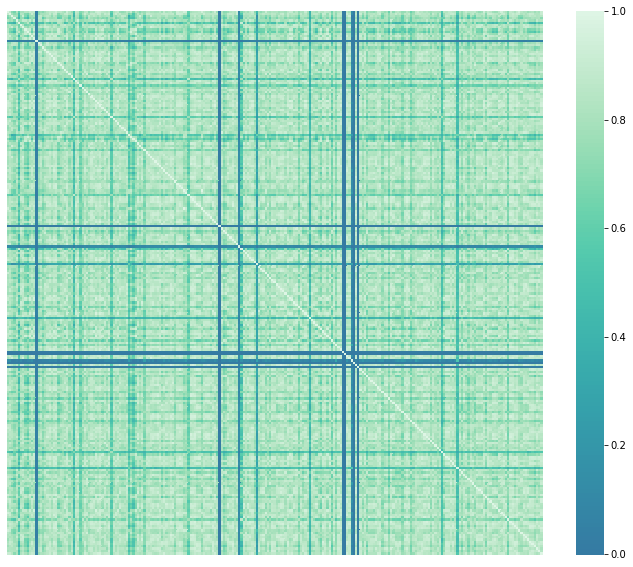

In [ ]:
plt.figure(figsize=(12,10))

corr = unfilt.corr()
midpoint = (corr.values.max() - corr.values.min()) /2 + corr.values.min()

sns.heatmap(corr,cmap="mako", center=0, yticklabels=False , xticklabels=False)

print("Average correlation between cells: ", midpoint)
print("Minimum correlation between cells: ", corr.values.min(), "\n")

We can see from the minimum value obtained that there are some cells that are completely uncorrelated from the others and we want to see why:

Text(0, 0.5, 'Frequency')

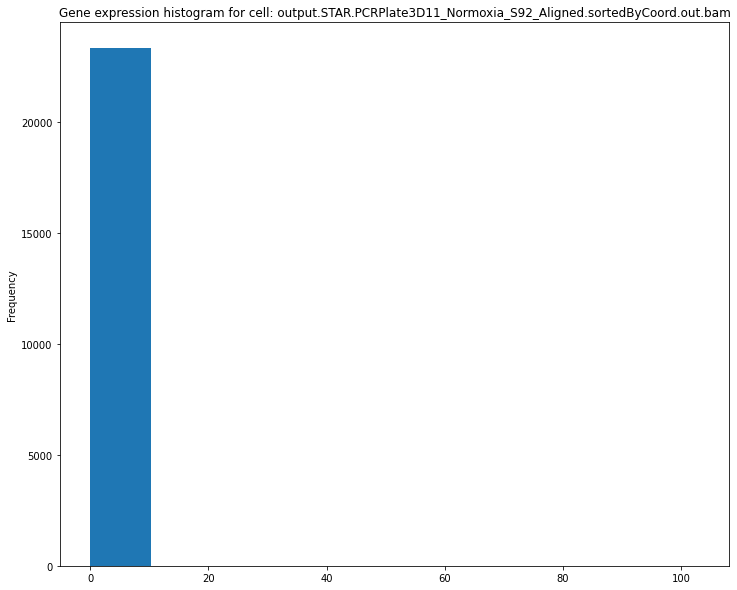

In [ ]:
plt.figure(figsize=(12,10))
#Given the symmetry of the table i look for low correlated cells in the first column, but
#that's completely arbirary
min  = np.argmin(list(corr[corr.columns.values[1]]))
plt.hist(unfilt.iloc[:,min])
plt.title(f"Gene expression histogram for cell: {unfilt.columns.values[min]}")
plt.ylabel("Frequency")

Here we can clearly see why. These cells have zero count for every gene. These cells are abnormal and therefore will need to be removed. We will treat this issue in full details in the part concerning filtering

We now want to analyse the structure among the covariates. Notice that here due to computational power issues we display the correlation just of the first 10% of the genes.

Average correlation between cells:  0.40951765039846083
Minimum correlation between cells:  -0.1809646992030784 



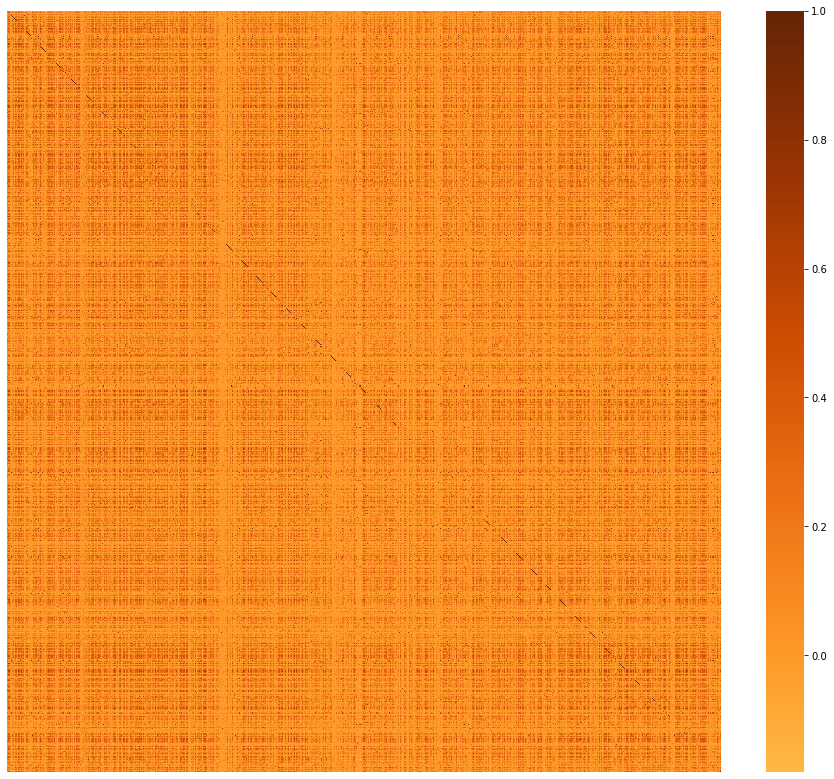

In [ ]:
plt.figure(figsize=(16,14))
#df_small = df.iloc[:, :50]
#c= df_small.corr()
corr = unfilt.iloc[:3000,:].T.corr()
midpoint = (corr.values.max() - corr.values.min()) /2 + corr.values.min()
#sns.heatmap(c,cmap='coolwarm',annot=True, center=midpoint )
sns.heatmap(corr,cmap="YlOrBr", center=0, yticklabels=False , xticklabels=False)

print("Average correlation between cells: ", midpoint)
print("Minimum correlation between cells: ", corr.values.min(), "\n")

Even if we are dealing with just the 10% of the data we can clearly see how there's not a well defined structure among the genes. This can be paroblem if we consider the dimension of the dataset, some more structure for sure would have helped us in dimensionality reduction, for example, or in the task to find the so called "meta-genes".


---

Given what we've seen in the table `unfilt` we suspect that our dataset will be probably very sparsed, so we want to quantify that sparsity in some way. The first and more intutive one is to calculate the average sparsity and to plot the table in some way



In [ ]:
#Avarage density of zeros in the data

print(f"The average sparsity of the table is: {(unfilt == 0).sum().sum() / (unfilt.shape[0] * unfilt.shape[1]) * 100}%")

The average sparsity of the table is: 55.76545995438026%


This is a pretty high value! our dataset is definitely sparsed.

In the following plot we color with blue the points in the table that are different from zero. This can give us an idea of how this high sparsity is distributed across the dataset




In [ ]:
plt.figure(figsize=(25, 600))
plt.spy(unfilt.iloc[:, :], markersize=1)

This very big graph is already telling us some interesting things about the data.

We can clearily see that some cells have a low overall number of genes expessed and this may be due to problems of measure, health of the single cell, lab mistakes, ecc...

At the same time we observe how some genes are constantly not expressed among almost all the cells, meaning that there is no need of producing that specific protein / activating that methabolic pathway / regulating that specific gene expression that the gene is encodning for .

Gene expression is thus inducing non homogeneity of the sparsity. This is actually a good thing! This sparsity is "well structured and it brings a biological meaning"! (clearily veasible some horizontal white lines). Our aim will be therefore to study this structure and drive our own conclusions from that.

The great limitation of this plot is that we don't have a differentiation among values of the expression (but we will have a more complete picture with an heatmap leater), to have an idea of that we use the function `describe()` on our dataset and we plot an histogram of the expression for some randomly choosen cells

In [ ]:
unfilt.describe()

,output.STAR.PCRPlate1A10_Normoxia_S123_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A1_Hypoxia_S97_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A8_Normoxia_S119_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
count,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,...,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000,23342.000000
mean,99.795947,208.126896,9.716391,151.004027,35.779496,47.197284,153.152643,136.182589,38.452660,45.617171,...,76.534359,105.796718,54.145146,29.829406,28.967484,104.975538,35.262874,108.445849,37.361109,76.472753
std,530.122968,982.196276,65.620267,978.042324,206.116742,545.993502,865.942966,871.712002,265.362499,367.122155,...,347.041462,537.480379,344.457045,186.932074,135.624956,445.260258,171.061263,589.740715,181.600602,369.500033
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000
75%,52.000000,126.000000,5.000000,40.000000,22.000000,17.000000,82.000000,76.000000,22.000000,18.000000,...,57.000000,67.000000,30.000000,18.000000,19.000000,76.000000,24.000000,68.000000,23.000000,45.000000
max,35477.000000,69068.000000,6351.000000,70206.000000,17326.000000,47442.000000,43081.000000,62813.000000,30240.000000,35450.000000,...,19629.000000,30987.000000,21894.000000,13457.000000,11488.000000,33462.000000,15403.000000,34478.000000,10921.000000,28532.000000


Text(0, 0.5, 'Frequency')

<Figure size 1440x1224 with 0 Axes>

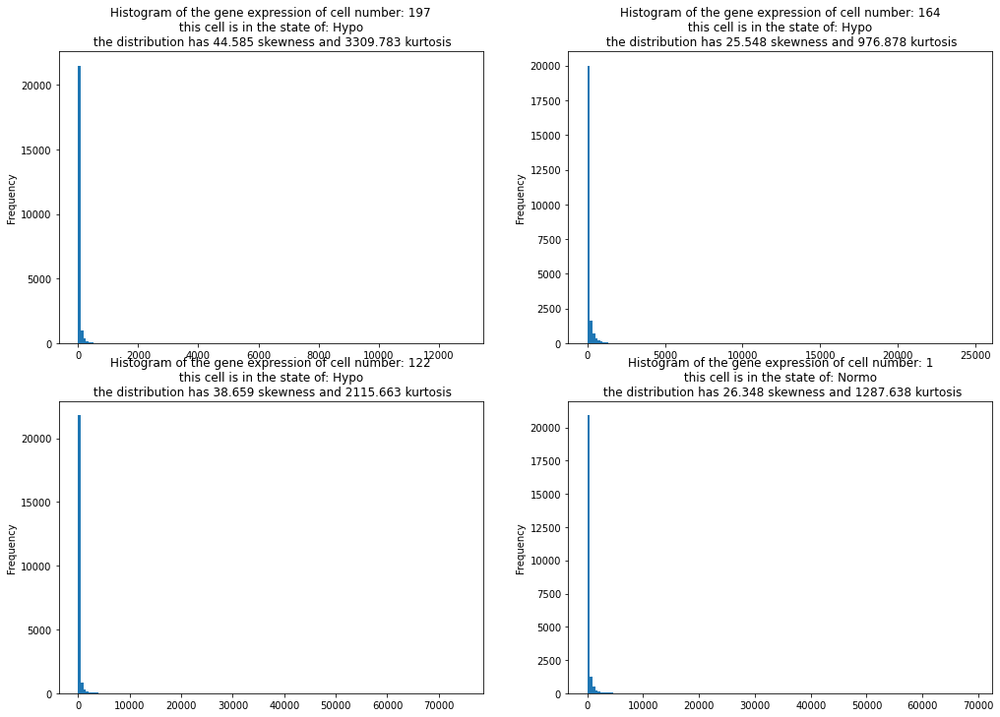

In [ ]:
from scipy.stats import kurtosis, skew

plt.figure(figsize=(20, 17))

first_cell = random.randrange(unfilt.shape[1])
second_cell = random.randrange(unfilt.shape[1])
third_cell = random.randrange(unfilt.shape[1])
fourth_cell = random.randrange(unfilt.shape[1])

plt.figure(figsize=(17, 12))

plt.subplot(2, 2, 1)
plt.hist(unfilt.iloc[:,first_cell], bins=150)
plt.title(f"Histogram of the gene expression of cell number: {first_cell}\n this cell is in the state of: {meta.iloc[first_cell, 3]} \n the distribution has {round(skew(unfilt.iloc[:,first_cell]), 3)} skewness and {round(kurtosis(unfilt.iloc[:,first_cell]), 3)} kurtosis")
plt.ylabel("Frequency")

plt.subplot(2, 2, 2)
plt.hist(unfilt.iloc[:,second_cell], bins=150)
plt.title(f"Histogram of the gene expression of cell number: {second_cell}\n this cell is in the state of: {meta.iloc[second_cell, 3]} \n the distribution has {round(skew(unfilt.iloc[:,second_cell]), 3)} skewness and {round(kurtosis(unfilt.iloc[:,second_cell]), 3)} kurtosis")
plt.ylabel("Frequency")

plt.subplot(2, 2, 3)
plt.hist(unfilt.iloc[:,third_cell], bins=150)
plt.title(f"Histogram of the gene expression of cell number: {third_cell}\n this cell is in the state of: {meta.iloc[third_cell, 3]} \n the distribution has {round(skew(unfilt.iloc[:,third_cell]), 3)} skewness and {round(kurtosis(unfilt.iloc[:,third_cell]), 3)} kurtosis")
plt.ylabel("Frequency")

plt.subplot(2, 2, 4)
plt.hist(unfilt.iloc[:,fourth_cell], bins=150)
plt.title(f"Histogram of the gene expression of cell number: {fourth_cell}\n this cell is in the state of: {meta.iloc[fourth_cell, 3]} \n the distribution has {round(skew(unfilt.iloc[:,fourth_cell]), 3)} skewness and {round(kurtosis(unfilt.iloc[:,fourth_cell]), 3)} kurtosis")
plt.ylabel("Frequency")



The result is as expected by choosing at random four cells in our sample. The histogram is showing how for these cells the big majority of genes have zero reads, but those who are not can count up to almost 45000 reads (seen from the table above). Moreover, from the values of kurtosis and skewness we see that the distributions are highly non normal

We leaen an important thing about this dataset, **the interesting datapoints are the outliers**! This means that we cannot procede with the elimination of the outliers as you would normally do, because it would leave us with no information at all

---

Now that we assessed that there are a lot of zeros in our dataset, we want to see for some genes how is the distributions on non-zero values, maybe there are some sort of clusters that we can identify (at least that's what we would expect: if the gene is expressed we will record a certain gene expression (more or less) and if it's not expressed we recover almost all zeros. Mathematically we would expect the histogram to show a binomodal behaviour with one of the peaks around zero.

Text(0, 0.5, 'Frequency (possibly scaled)')

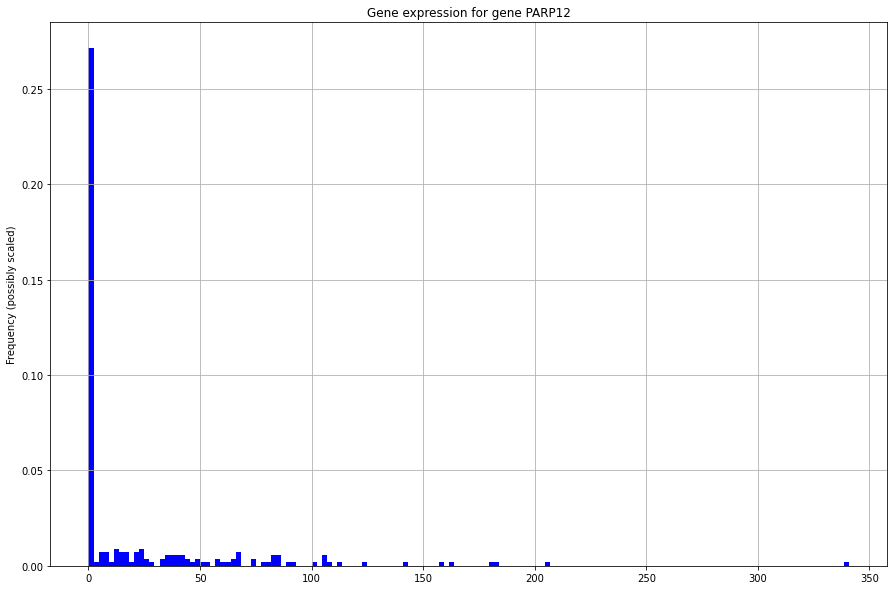

In [ ]:
rdn_gene = random.randrange(unfilt.shape[0])

plt.figure(figsize=(15, 10))
unfilt.iloc[rdn_gene, :].plot.hist(grid=True,
                                      density = True,
                                      bins=150,
                                      color='blue')

plt.title(f"Gene expression for gene {unfilt.index[rdn_gene]}")
plt.ylabel("Frequency (possibly scaled)")

But we see that this is not the case!  All the other genes will display a similar distribution and we point out three important common characteristics:
- A low number of counts associated with a large proportion of genes
- A long right tail due to the lack of any upper limit for expression
- A large dynamic range

The distribution seems therefor to follow a Poisson/Negative binomial distribution. (where in the first case we assume the mean to be equal to the variance and in the second case we don't). The intuition of why is that the case is the following:

**With RNA-Seq data, a very large number of RNAs are represented and the probability of pulling out a particular transcript is very small**

Under this light, this really resables the canonical examples of "customers entering the shop in a fixed interval of time" or "Number of accidents in a day an insurance company will have to pay for" that are typically used to explain the Poisson Distribution.

---
Given what stated above, we further investigate the ralation between mean and variance of the gene expression among cells to see if we would prefer adopting a Negative Binomial ditribution:

Text(0, 0.5, 'Variance')

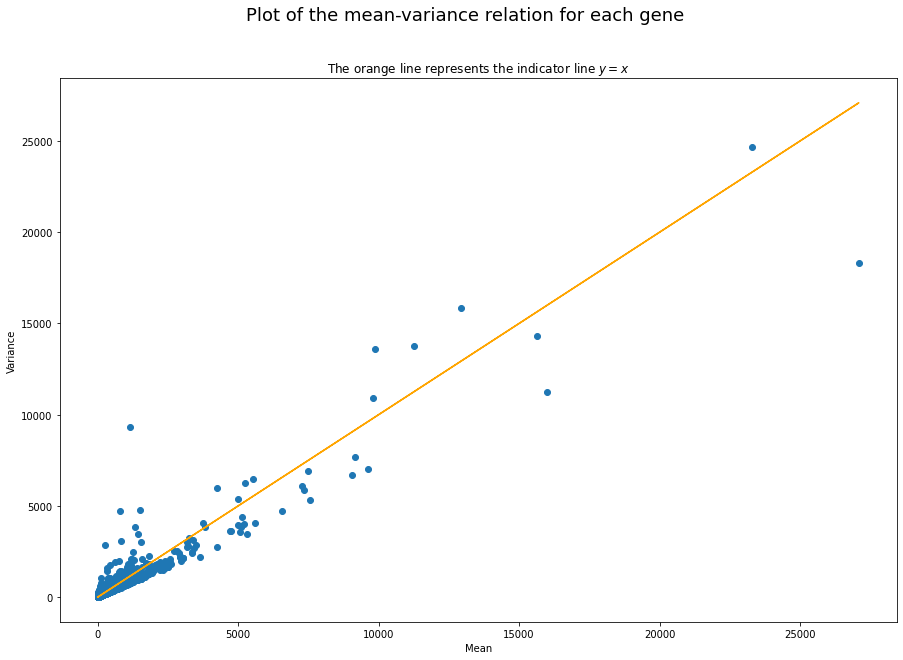

In [ ]:
##################### THIS PLOT COULD TAKE SOME TIME ########################
mean_vector = unfilt.T.describe().iloc[1,:]
var_vector = unfilt.T.describe().iloc[2,:]

plt.figure(figsize=(15, 10))
plt.scatter(mean_vector, var_vector)
plt.plot(mean_vector, mean_vector, color = "orange")
plt.title("The orange line represents the indicator line $y=x$", fontsize = 12)
plt.suptitle("Plot of the mean-variance relation for each gene", fontsize = 18)
plt.xlabel("Mean")
plt.ylabel("Variance")



Clearly we see that there's a sort of linear 1:1 relation between mean and variance, we can try to use the Poisson distribution to model the gene expression and use it to identify **HVG** (Highly Variable Genes). Those will be the genes we want to keep when filtering (See the next part)

##Filtering and Normalization

###Cells filtering

We now check if the total reads among cells follow a normal distribution, meaning that the difference in total read counts it's just a measurement error. This is reasonable given that we expect the same cell-line grown in just two different states to show more or less the same total gene expression.

Moreover, we remind that in the experiment two other kind of normalizations are applyed to reduce possible problems in the total read count:
- We extract the same amount of Rna (In the LAB)
- We adjust the runs to get similar number of counts for each sample (in the sequencing facilities)

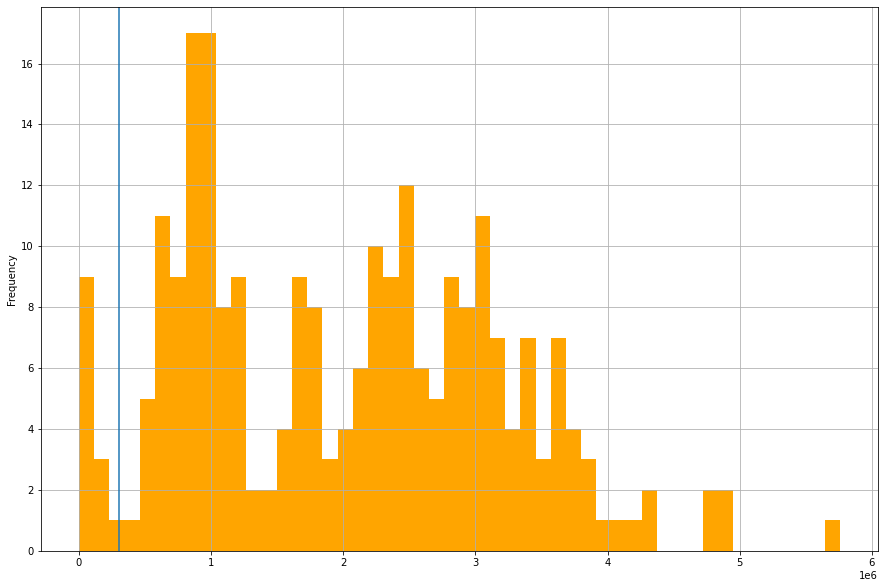

In [ ]:
totsums = unfilt.sum(axis = 0)

plt.figure(figsize=(15, 10))
plt.axvline(x=0.30e6) #Where do we want to do the cut in our filtering
totsums.plot.hist(grid = True, bins = 50, color= "orange")

Now we want to plot an istogram of the number of genes different from zero for each cell, also this should follow a normal distribution (this is a stadard step in each analysis)

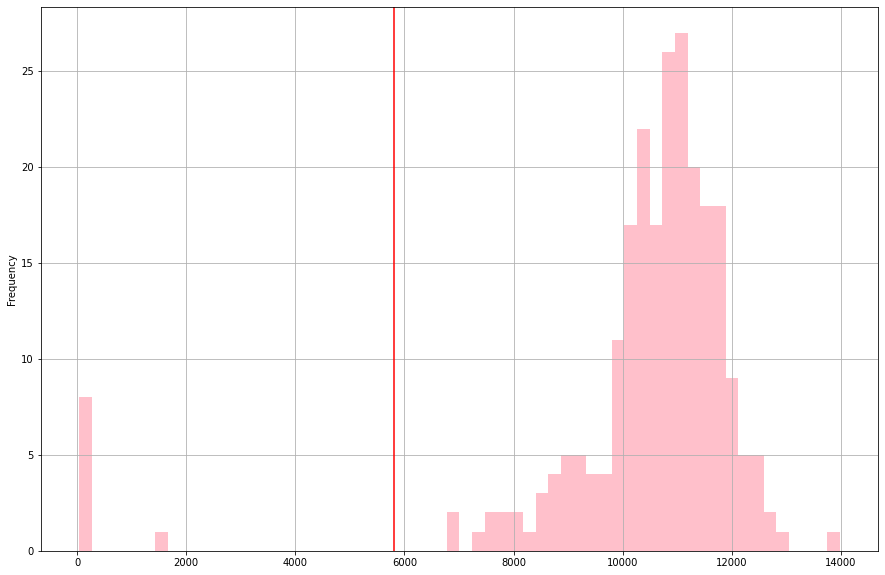

In [ ]:
#Create a copy dataframe where all the positive entries will become equal to one
copy = unfilt.copy()
copy[copy != 0] = 1
totcopysums = copy.sum(axis = 0)

plt.figure(figsize=(15, 10))
plt.axvline(x=5800, color = "red") #Where do we want to do the cut in our filtering
totcopysums.plot.hist(grid = True, bins = 60, color= "pink")

The plots are suggesting that indeed there's a measuement error following a normal distribution and therefore we would like to cut those cells that do not follow this curve, because their gene expression may be corrupted by human mistakes in extracting the data or by the health status of the cell itself

The blue vertical line in the first plot and the red one in the second indicate where (by eye) the plot finishes to be a nice bell-shaped histogram and thus where we want to cut in the filtering.


---

Here we proceed with the above described filtering

In [ ]:
filtered  = unfilt.loc[:, (totsums >= .30e6) & (copy.sum(axis = 0) >= 5800)]
perc_cell_lost = (unfilt.shape[1] - filtered.shape[1]) / unfilt.shape[1] * 100
print(f" We passed from haveing {unfilt.shape[1]} cells to have {filtered.shape[1]} cells\n This results in a lost of the {perc_cell_lost}% of the cells")

 We passed from haveing 243 cells to have 230 cells
 This results in a lost of the 5.349794238683128% of the cells


In [ ]:
filtered

,output.STAR.PCRPlate1A10_Normoxia_S123_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A8_Normoxia_S119_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A9_Normoxia_S20_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
WASH7P,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CICP27,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DDX11L17,0,0,0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
WASH9P,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
OR4F29,2,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-TE,22,43,0,0,3,47,4,2,8,17,...,24,15,15,4,4,26,1,4,4,20
MT-CYB,4208,6491,4819,310,695,2885,1552,366,1829,3387,...,1119,1429,808,999,916,3719,984,2256,981,2039
MT-TT,26,62,11,4,0,41,9,2,8,9,...,48,31,3,8,5,42,1,15,6,34
MT-TP,66,71,3,9,14,91,22,3,30,37,...,119,52,11,22,15,48,18,36,8,79


We now want to study the percentage of mitochondrial RNA and cut those cells at a rate that is too high (above 4%/5% is the rule of thumb that we adopt here, but in general this trashold is study-specific and there's active discussion inside the community about how to decide it). The idea behind this filtering is that when a cell is lysed during the process of Rna extraction or the cell membrane is disrupted, the cytoplasmatic transcript is released while mitochondrial RNA is more protected because of a double membrane around mitochondria. Therefore the high percentage of mtRNA would indicate poor quality of the cell condition

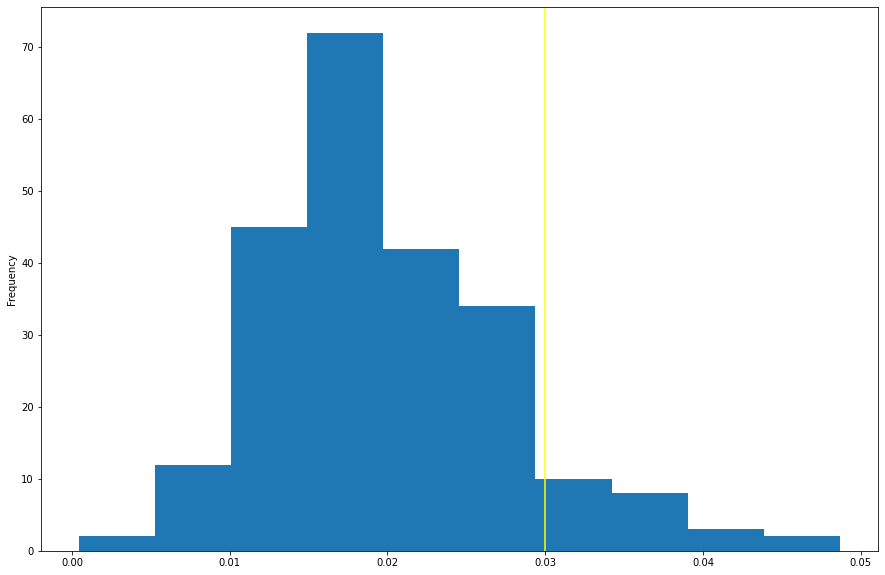

In [ ]:
total_mitocondrial = filtered[filtered.index.str.startswith('MT-')].sum(axis = 0)
total_express = filtered.sum(axis = 0)
assert len(total_mitocondrial) == len(total_express)

mito_ratio = total_mitocondrial / total_express

plt.figure(figsize=(15, 10))
plt.axvline(x=0.03, color = "yellow") #Where do we want to do the cut in our filtering
mito_ratio.plot.hist()

We filter cells with too much mitocondrial RNA

In [ ]:
filtered_cells = filtered.loc[:, mito_ratio <= 0.03]
filtered_cells

,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A9_Normoxia_S20_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B11_Normoxia_S127_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B12_Normoxia_S27_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
WASH7P,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
CICP27,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DDX11L17,0,0,0,1,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
WASH9P,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,1,0,0
OR4F29,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-TE,43,0,0,3,47,4,2,17,17,15,...,24,15,15,4,4,26,1,4,4,20
MT-CYB,6491,4819,310,695,2885,1552,366,3387,7107,2384,...,1119,1429,808,999,916,3719,984,2256,981,2039
MT-TT,62,11,4,0,41,9,2,9,25,9,...,48,31,3,8,5,42,1,15,6,34
MT-TP,71,3,9,14,91,22,3,37,88,53,...,119,52,11,22,15,48,18,36,8,79


And this is the end for us of the filtering of the cells.

---

### Normalization

We first recall what is the distribution of a randomly choosen gene, this time within the cells that passed the filtering section

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


Text(0.5, 1.0, 'Gene expression for gene SLC2A11')

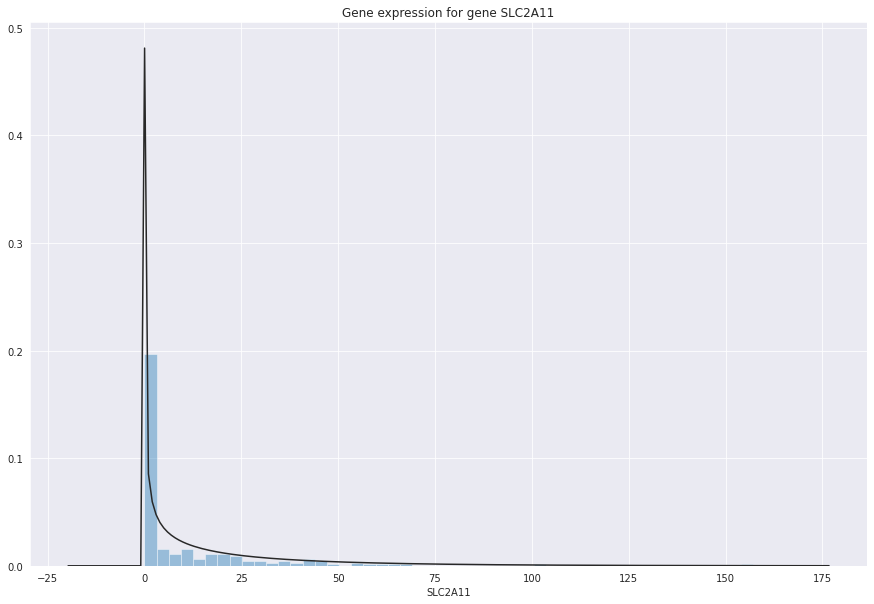

In [ ]:
rdn_gene = random.randrange(filtered_cells.shape[0])
plt.figure(figsize=(15, 10))
sns.set_style('darkgrid')
sns.distplot(filtered_cells.iloc[rdn_gene, :], fit=stats.gamma,
                                          kde=False,
                                          bins = 50)
plt.title(f"Gene expression for gene {unfilt.index[rdn_gene]}")


Here you see an histogram with a gamma distribution fitted. Why a gamma distribution? This is because we want a smooth and contiuos verion of the Poisson distribution (that would be an Exponential), but with a bit more of freedom so we fitted a Gamma (Sum of Exponentials)

We now want to check that normalizing for total reads across cells will change the distribution for our single gene. This is a normalization in Cell dimension and reading depth, if we want to perform comparisons within cells we need them to be indeed comparable. This kind of normalization is commonly known as **Library Size Normalization**.

In [ ]:
unfilt_CPM = filtered_cells.copy()

#CPM normalization
for i in range(unfilt_CPM.shape[1]):
  unfilt_CPM.iloc[:,i] = unfilt_CPM.iloc[:,i]/(sum(unfilt_CPM.iloc[:,i])/10e6)


/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


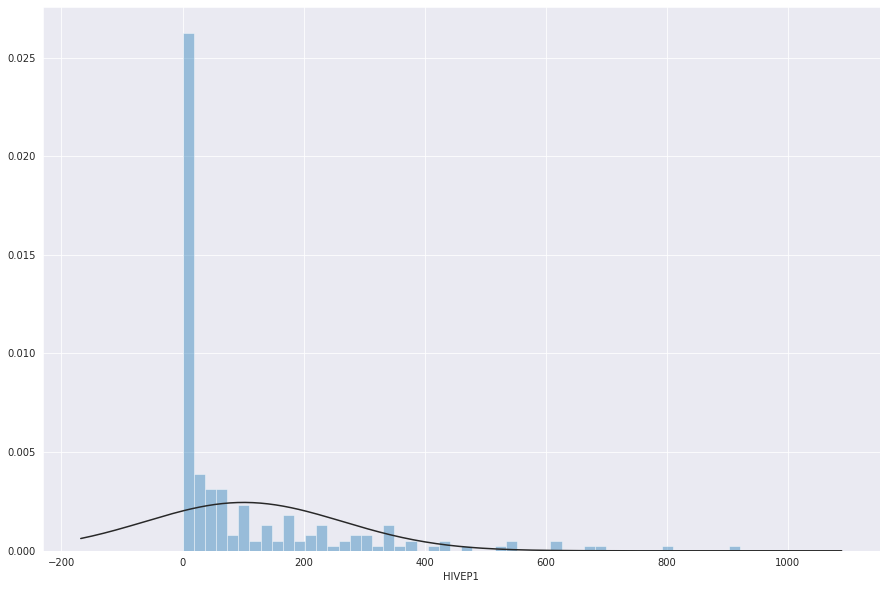

In [ ]:
rdn_gene = random.randrange(filtered_cells.shape[0])

plt.figure(figsize=(15, 10))
sns.set_style('darkgrid')
sns.distplot(unfilt_CPM.iloc[rdn_gene, :], fit=stats.norm,
                                          kde=False,
                                          bins = 50)

We have the concern that this:
- artificially increases variance for genes espressed around zero
- Inflation on gene counts for cell types with low transcript numbers
- topological distorsion in the cell neightborhood structure, affecting clustering distance matrix

These are a major concern when you want to compare the gene expression. To better understand that consider the following example: you have two cells where a single gene $X$ is upregulated in cell $A$ compared to cell $B$. What happens is that when $X$ is assigned more reads or UMIs, the library size factor is increasing and is yielding smaller normalized expression values for all non-DE genes . In such a case, the net effect is that non-DE genes in $A$ will incorrectly appear to be downregulated compared to $B$. This baias get worse and worse the more gene $X$ is upregulated in cell $A$ compared to cell $B$

In CPM normalization is assumed that the only difference between samples is total counts and this is of course a very strict and quite naive assumption. What is usually done is to use some normalization teqniques that try to calculate a normalization factor that keeps into account not only the total count on the cell, but also the distribution of the genes. Investigating this issue is a bit behond the scope of this project so we will limit ourself to a CPM normalization.

Notice that given the fact that we are not using UMI counts for this specific datset, but just normal counts we would also need to normalize for the gene lenght. The idea here is that longer genes will recive more reads than sorter ones, but this for us will not be a problem as long as we just make relative comparisons for the same gene among the different samples (that is exactly what we will do soon trying to find out the Highly expressed genes)

In [ ]:
#Log + 1 transfomration
Normal = np.log(unfilt_CPM.copy() + 1)
Normal

,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A9_Normoxia_S20_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B11_Normoxia_S127_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B12_Normoxia_S27_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
WASH7P,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.119858,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CICP27,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
DDX11L17,0.000000,0.000000,0.000000,2.310261,0.000000,0.000000,0.000000,1.839774,1.276152,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
WASH9P,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.496612,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.625521,0.000000,1.599483,0.000000,0.000000
OR4F29,0.000000,0.000000,0.000000,0.000000,1.334288,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-TE,4.494373,0.000000,0.000000,3.340426,4.886376,2.608853,3.147706,4.511045,3.804617,3.464681,...,4.907816,4.122946,4.784858,4.068143,4.096969,4.673835,2.576354,2.821491,3.847318,4.727769
MT-CYB,9.500185,9.523174,8.219553,8.749820,8.996055,8.493594,8.313537,9.794540,9.817775,8.501586,...,8.742697,8.663470,8.763136,9.571416,9.514002,9.627635,9.388965,9.095296,9.328117,9.343454
MT-TT,4.856878,3.472215,3.889670,0.000000,4.750904,3.378024,3.147706,3.884775,4.183129,2.974496,...,5.597262,4.840488,3.208295,4.752699,4.316783,5.149846,2.576354,4.098620,4.245645,5.254748
MT-TP,4.991437,2.252478,4.689172,4.852645,5.543431,4.251478,3.538750,5.282793,5.430612,4.704238,...,6.502970,5.354548,4.477737,5.758794,5.406460,5.282652,5.392190,4.964361,4.529739,6.094856


We now look at the effect of this normalization on the distribution of a random gene.

N.B: you can run this cell multiple times to see different genes choosen. As you can see it's not difficult to find genes with almost all zero reads (we will take care of this issue soon)

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


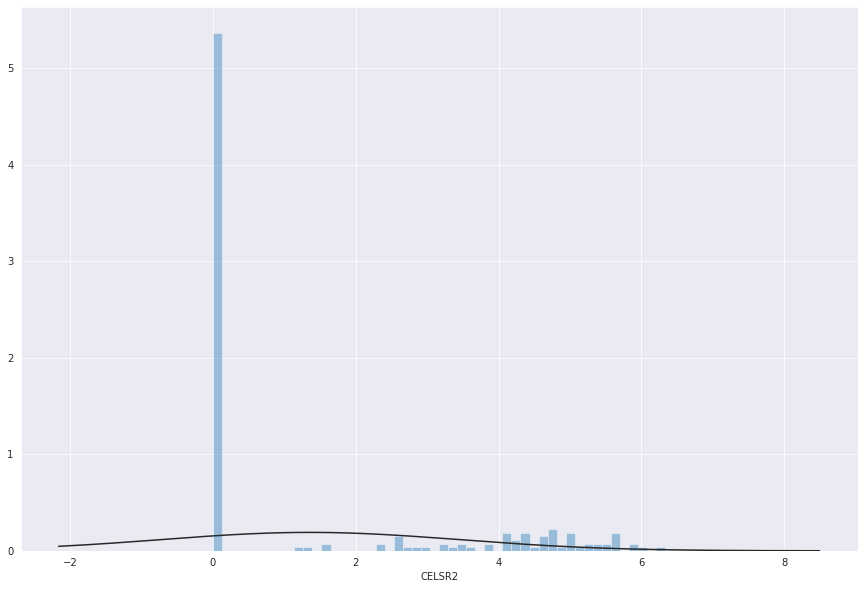

In [ ]:
rdn_gene = random.randrange(filtered_cells.shape[0])

plt.figure(figsize=(15, 10))
sns.set_style('darkgrid')
sns.distplot(Normal.iloc[rdn_gene, :], fit=stats.norm,
                                          kde=False,
                                          bins = 50)

In [ ]:
Normal

,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A9_Normoxia_S20_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B11_Normoxia_S127_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B12_Normoxia_S27_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
WASH7P,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.119858,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CICP27,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
DDX11L17,0.000000,0.000000,0.000000,2.310261,0.000000,0.000000,0.000000,1.839774,1.276152,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
WASH9P,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.496612,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.625521,0.000000,1.599483,0.000000,0.000000
OR4F29,0.000000,0.000000,0.000000,0.000000,1.334288,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-TE,4.494373,0.000000,0.000000,3.340426,4.886376,2.608853,3.147706,4.511045,3.804617,3.464681,...,4.907816,4.122946,4.784858,4.068143,4.096969,4.673835,2.576354,2.821491,3.847318,4.727769
MT-CYB,9.500185,9.523174,8.219553,8.749820,8.996055,8.493594,8.313537,9.794540,9.817775,8.501586,...,8.742697,8.663470,8.763136,9.571416,9.514002,9.627635,9.388965,9.095296,9.328117,9.343454
MT-TT,4.856878,3.472215,3.889670,0.000000,4.750904,3.378024,3.147706,3.884775,4.183129,2.974496,...,5.597262,4.840488,3.208295,4.752699,4.316783,5.149846,2.576354,4.098620,4.245645,5.254748
MT-TP,4.991437,2.252478,4.689172,4.852645,5.543431,4.251478,3.538750,5.282793,5.430612,4.704238,...,6.502970,5.354548,4.477737,5.758794,5.406460,5.282652,5.392190,4.964361,4.529739,6.094856


---

##Data filtering


###Assuming normality of the transformed data

In this section we try to find the Higly Variable genes and keep them, discarding all the others. In this first version of the filtering we use the data $log( x + 1)$ transformed.

First of all we divide our normalized and filtered with respect to cells dataframe `Normal` into two smaller dataframes: one containing the cells that grew up under Hypoxia `meta["Condition"] == "Hypo"` and one containing the cells that grew up under Normoxia `meta["Condition"] == "Norm"`

In [ ]:
t_norm = Normal.T.copy()

#We divide the dataset in two subdatasets containing the hypoxic and the normal cells
hypo = t_norm[meta["Condition"] == "Hypo"].T
norm = t_norm[meta["Condition"] == "Normo"].T

hypo.columns = hypo.columns.str.replace("output.STAR.", "")
hypo.columns = hypo.columns.str.replace("_Aligned.sortedByCoord.out.bam", "")

norm.columns = norm.columns.str.replace("output.STAR.", "")
norm.columns = norm.columns.str.replace("_Aligned.sortedByCoord.out.bam", "")


/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  after removing the cwd from sys.path.
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  """
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:7: FutureWarning: The default value of regex will change from True to False in a future version.
  import sys
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:8: FutureWarning: The default value of regex will change from True to False in a future version.
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:10: FutureWarning: The default value of regex will change from True to False in a future version.
  # Remove the CWD from sys.path while we load stuff.
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:11: FutureWarning: The default value of regex will change from True 

Now we have a look to the result for the new dataframe `hypo` and we check if the dimensions of the two dataframes are similar

In [ ]:
print(f"The dataframe hypo has dimension: {hypo.shape} \nThe dataframe norm has dimension: {norm.shape}")
hypo

The dataframe hypo has dimension: (23342, 110) 
The dataframe norm has dimension: (23342, 99)


,PCRPlate1A2_Hypoxia_S104,PCRPlate1A3_Hypoxia_S4,PCRPlate1A4_Hypoxia_S8,PCRPlate1A5_Hypoxia_S108,PCRPlate1A6_Hypoxia_S11,PCRPlate1B2_Hypoxia_S1,PCRPlate1B3_Hypoxia_S5,PCRPlate1B5_Hypoxia_S109,PCRPlate1B6_Hypoxia_S12,PCRPlate1C1_Hypoxia_S99,...,PCRPlate4E2_Hypoxia_S196,PCRPlate4E3_Hypoxia_S227,PCRPlate4F1_Hypoxia_S224,PCRPlate4F2_Hypoxia_S197,PCRPlate4F4_Hypoxia_S228,PCRPlate4F5_Hypoxia_S229,PCRPlate4G1_Hypoxia_S193,PCRPlate4G2_Hypoxia_S198,PCRPlate4G6_Hypoxia_S232,PCRPlate4H2_Hypoxia_S199
WASH7P,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CICP27,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.862838,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
DDX11L17,0.000000,0.000000,2.310261,0.000000,0.000000,3.613948,3.044451,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
WASH9P,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.889376,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.599483
OR4F29,0.000000,0.000000,0.000000,1.334288,0.000000,2.305389,2.397827,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-TE,0.000000,0.000000,3.340426,4.886376,2.608853,2.947390,3.433915,3.050472,2.730650,4.443719,...,4.457283,4.205359,4.569119,4.083044,3.192022,4.039419,4.122946,4.784858,4.068143,2.821491
MT-CYB,9.523174,8.219553,8.749820,8.996055,8.493594,8.300906,8.973403,8.787494,9.528173,9.827093,...,9.775171,8.853441,8.316030,8.485091,8.545023,9.548771,8.663470,8.763136,9.571416,9.095296
MT-TT,3.472215,3.889670,0.000000,4.750904,3.378024,2.947390,0.000000,3.719667,3.390666,3.368339,...,4.057598,4.343173,4.910931,4.366503,4.607016,4.502798,4.840488,3.208295,4.752699,4.098620
MT-TP,2.252478,4.689172,4.852645,5.543431,4.251478,3.831688,3.433915,4.117018,4.619073,5.492078,...,5.297934,5.592779,5.641063,4.482874,5.203272,4.984036,5.354548,4.477737,5.758794,4.964361


We want to identify those genes for which we can see a statistically significant difference in the ditribution of the genes expression among all the cells. Those will be the genes that we want to keep for our furure studies.

We start by applying a t-test to obtain some raw p-values that identify statistically significant genes. Here is where we naively assume normality of the data, leveraging on the central limit theorem given that the two sample sizes are respectively 158 and 146)

In [ ]:
#We create a dict to store the inial un adjusted p-values
p_val_row = {}
for i in range(Normal.shape[0]):
  p_val_row[i] = stats.ttest_ind(hypo.iloc[i,:], norm.iloc[i,:], equal_var=False).pvalue

We plot the result on an histogram that is as would expect: A lot of genes seems statistically significant and then you have an "under layer" of uniform distribution coming from the non significant expressed genes.

Text(0.5, 1.0, 'p-value histogram')

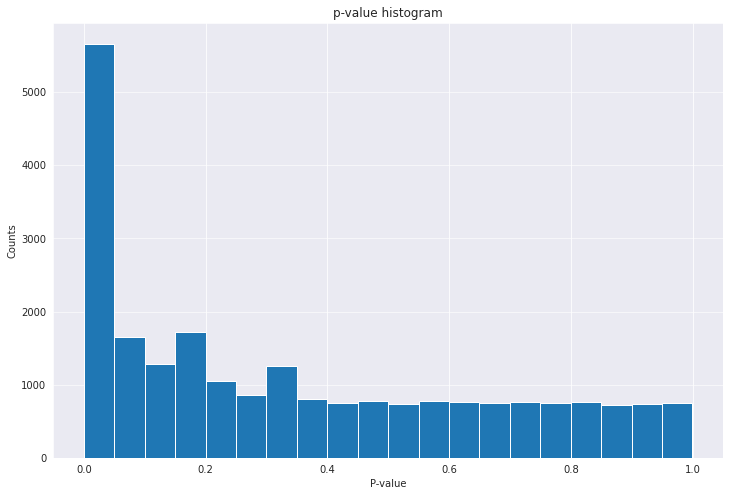

In [ ]:
plt.figure(figsize=(12,8))
plt.hist(p_val_row.values(),
         bins = 20)
plt.grid(axis='y', alpha=0.75)
plt.xlabel('P-value')
plt.ylabel('Counts')
plt.title('p-value histogram')

Of course, when having to deal with so many tests we will incur in the so called "Multiple Testing Problem" and one way to deal with it is to change the p-values into q-values using the Benjamini-Hochberg correction. These values are also known as FDRs (False Discovery Rates) and we write down a function called `q-value` that computes them.

Sometimes, however, the Benjamini-Hochberg correction is very good ad eliminating False positives, but sometimes it shriks too much the number of true positive, when adjusting the p-values. This eccesive shrinking behaviour can lead to a significant loss of important genes and we have to account for that.

This is exactly what we do in the next part:
- We try different CPM trashold (see the description of the function)
- We calculate the ajusted p-values on the genes that come out of this procedure



In [ ]:
def filter_CPM(treshold):
  '''
  This function takes as input a CPM trashold and then it looks for each gene if there are
  at least two cells with the CPM that is over the given trashold. It then stores the indices
  of the genes that did NOT pass this barrier test.
  '''
  to_filter_list = []
  for i in range(Normal.shape[0]):
    mask = [element for element in Normal.iloc[i,:] if element >= treshold]
    if len(mask) <= 2:
      to_filter_list.append(i)
  return to_filter_list

And here we apply this test with a trashold of `CPM = 1`

In [ ]:
len(filter_CPM(5))

9586

In [ ]:
def q_value (p_val_dict):
  sorted_list = [[key, value] for (key, value) in sorted(p_val_dict.items(), key=lambda x: x[1])]
  rank = 1
  for p in sorted_list:
    p[1] = p[1] * len(p_val_dict)/rank
    rank += 1
  q_val_dict = dict(sorted_list)
  q_val_dict = (sorted(q_val_dict.items()))
  return q_val_dict

In [ ]:
def graph_data_due(p_val_pre):
  y_axis = []
  for treshold in np.arange(0, 20, 1):
    aux_dictt = p_val_pre.copy()
    indices = filter_CPM(treshold)
    print("how many genes will be ignored in this iteration", len(indices))
    for ind in indices:
      del aux_dictt[ind]
    count = len([value for value in q_value(aux_dictt) if value[1] <= 0.05])
    print("Relevant number of genes for this treshold", count)
    y_axis.append(count)
    aux_dictt = p_val_pre.copy()
  return y_axis


In [ ]:
#Calculating this values will take some time, it has to go 20 iterations
y = graph_data_due(p_val_row)

how many genes will be ignored in this iteration 0
Relevant number of genes for this treshold 4231
how many genes will be ignored in this iteration 1901
Relevant number of genes for this treshold 3356
how many genes will be ignored in this iteration 3398
Relevant number of genes for this treshold 3437
how many genes will be ignored in this iteration 5474
Relevant number of genes for this treshold 3525
how many genes will be ignored in this iteration 7378
Relevant number of genes for this treshold 3536
how many genes will be ignored in this iteration 9586
Relevant number of genes for this treshold 3497
how many genes will be ignored in this iteration 12665
Relevant number of genes for this treshold 3262
how many genes will be ignored in this iteration 17118
Relevant number of genes for this treshold 2453
how many genes will be ignored in this iteration 21194
Relevant number of genes for this treshold 1105
how many genes will be ignored in this iteration 22838
Relevant number of genes fo

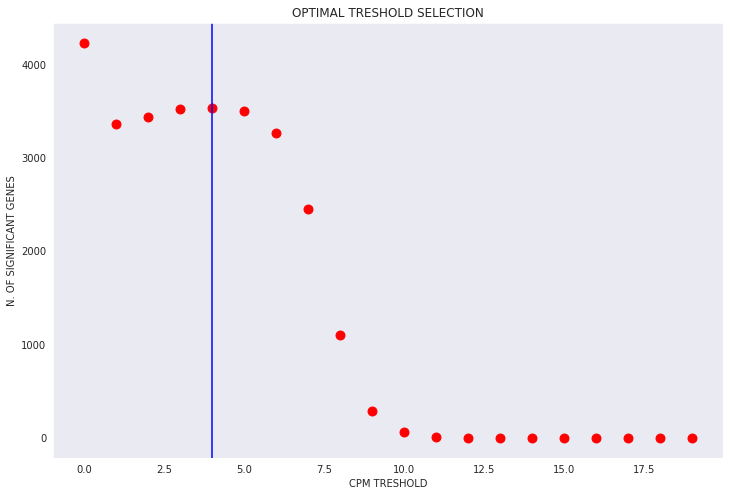

In [ ]:
x = np.arange(0, 20, 1)
plt.figure(figsize=(12,8))
plt.scatter(x, y,
            s = 80,
            color = "r")
plt.grid()
plt.xlabel('CPM TRESHOLD')
plt.ylabel('N. OF SIGNIFICANT GENES')
plt.title('OPTIMAL TRESHOLD SELECTION')
plt.axvline(x=4, color = "blue")
plt.show()

Given that we want to preserve as many significant genes as possible when adjusting the p-values, we choose a CMP cut of 3

In [ ]:
#We calculate the optimal set of genes
indices = filter_CPM(4)
final_dictt = p_val_row.copy()

for ind in indices:
  del final_dictt[ind]

#Notice that the sensitivity setted is very very small: 0.001%
final_indices = [value[0] for value in q_value(final_dictt) if (value[1] <= 0.05)]

We apply this to the dataset we had to finally obtain the final filtered version

In [ ]:
filt_lollo_1 = Normal.copy().iloc[final_indices]
filt_lollo_1

,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A9_Normoxia_S20_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B11_Normoxia_S127_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B12_Normoxia_S27_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
MTND1P23,6.772817,5.191494,5.781636,6.601558,6.750134,5.556678,6.241249,6.404638,6.165922,5.936978,...,7.046227,6.128137,5.921251,5.963004,6.251190,6.391642,6.110395,5.795721,6.291457,7.241321
MTND2P28,5.331955,3.837159,3.608782,2.310261,5.282240,3.264497,4.037888,5.255535,5.230914,3.249328,...,5.024778,4.960946,4.163534,4.068143,4.096969,5.261706,4.302640,4.783435,4.397747,5.365424
MTATP6P1,8.125904,7.524896,6.994488,7.287838,8.153417,7.229034,7.552846,8.235127,8.448522,7.194849,...,7.767775,7.605640,7.602307,7.806662,8.055522,7.871329,7.662512,7.832570,7.527590,7.869863
MTCO3P12,5.928611,5.310412,4.888170,5.155970,5.487146,4.738400,5.359810,5.903624,6.001219,4.400754,...,5.338081,4.988922,5.019487,5.558824,5.406460,5.672484,5.392190,5.290908,4.845248,5.441068
AGRN,5.923116,7.426881,3.216768,4.415141,4.843226,5.671327,0.000000,5.384952,5.567831,4.906660,...,5.868313,4.302565,3.702819,5.441522,5.003236,5.897744,5.392190,4.221829,6.466364,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-ATP6,9.169457,8.654302,7.881252,8.358717,9.272553,8.051159,8.422145,9.272768,9.459936,8.075675,...,8.740012,8.641541,8.534759,8.817472,8.760177,8.924556,8.648034,8.811779,8.535477,8.845355
MT-CO3,9.577100,8.989522,8.428350,8.797575,9.480422,8.574612,8.950374,9.673881,9.855331,8.374295,...,8.688539,8.883635,8.890753,9.283423,9.399634,9.414806,8.971273,9.265261,9.047574,9.267049
MT-TE,4.494373,0.000000,0.000000,3.340426,4.886376,2.608853,3.147706,4.511045,3.804617,3.464681,...,4.907816,4.122946,4.784858,4.068143,4.096969,4.673835,2.576354,2.821491,3.847318,4.727769
MT-CYB,9.500185,9.523174,8.219553,8.749820,8.996055,8.493594,8.313537,9.794540,9.817775,8.501586,...,8.742697,8.663470,8.763136,9.571416,9.514002,9.627635,9.388965,9.095296,9.328117,9.343454


Last, we try to implement a function that returns the name of the n most significant genes, based on the adjusted p_values calculated before

In [ ]:
def top_genes (n):
  sorted_list = [[key, value] for (key, value) in sorted(p_val_row.items(), key=lambda x: x[1])]
  rank = 1
  for p in sorted_list:
    p[1] = p[1] * len(p_val_row)/rank
    rank += 1

  indices = []
  for couple in sorted_list[:n]:
    indices.append(couple[0])

  for index in indices:
    print(Normal.index.values[index])


In [ ]:
top_genes(20)

EGLN3
SLC2A1
C4orf3
DANT1
LOXL2
PGK1
PLIN2
SLC6A8
BNIP3L
PNCK
EGLN1
BRIX1
LDHAP4
ARRDC3
SAP30-DT
NOP16
PAM
CCT6A
SEC61G
PNO1


Luckly enough at position #3 (NDRG1) and #11 (PGK1) we find two genes that we know are directly involved in the cell reaction to hypoxia (According to [DAVID Database](https://david.ncifcrf.gov/)). This little naive and baiased filtering gave us some nice results at the end and that's why we wanted to include it in the discussion

- **NDRG1**: This gene is a member of the N-myc downregulated gene family which belongs to the alpha/beta hydrolase superfamily. The protein encoded by this gene is a cytoplasmic protein involved in stress responses, hormone responses, cell growth, and differentiation. The encoded protein is necessary for p53-mediated caspase activation and apoptosis. Mutations in this gene are a cause of Charcot-Marie-Tooth disease type 4D, and expression of this gene may be a prognostic indicator for several types of cancer.

- **PGK1**:	The protein encoded by this gene is a glycolytic enzyme that catalyzes the conversion of 1,3-diphosphoglycerate to 3-phosphoglycerate. The encoded protein may also act as a cofactor for polymerase alpha. Additionally, this protein is secreted by tumor cells where it participates in angiogenesis by functioning to reduce disulfide bonds in the serine protease, plasmin, which consequently leads to the release of the tumor blood vessel inhibitor angiostatin.

In [ ]:
proffilt = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/AILAB/HCC1806_Filtered_Normalised_3000_Data_train.txt', delimiter = " ", index_col = 0)

In [ ]:
counter = 0
for gene in filt_lollo_1.index.values:
  if gene in proffilt.index.values:
    counter +=1

print(f"Sovrapposition between our dataframe and the provided dataframe: {counter/3000 *100}%")

Sovrapposition between our dataframe and the provided dataframe: 20.233333333333334%


---

---
###Nonparametric estimate

The idea here is to use not normalized data for filtering out genes, given that normalization as described above does not correct for library composition bias. Here the idea is to take the data as they are and perform the filtering in a similar way than before

To avoid numerical problem when applying the test and to stabilize the result we decide to cut all those genes with a CPM  

This also makes sense heuristically, because we dont want to calssify as significantly DE gene one that passes from mean count $0.2$ to mean count $0.8$ (The mean expression is four times higher, but given the low range of values this could be misleading)  

In [ ]:
def filter_CPM_keep_np(treshold):
  '''
  This function takes as input a CPM trashold and then it looks for each gene if there are
  at least two cells with the CPM that is over the given trashold. It then stores the indices
  of the genes that did NOT pass this barrier test.
  '''
  to_keep_list = []
  for i in range(filtered_cells.shape[0]):
    mask = [element for element in filtered_cells.iloc[i,:] if element >= treshold]
    if len(mask) >= 2:
      to_keep_list.append(i)
  return to_keep_list

np_to_keep_ind = filter_CPM_keep_np(1)
np_filt_1 = filtered_cells.copy().iloc[np_to_keep_ind]

In [ ]:
np_filt_1

,output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A4_Hypoxia_S8_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A5_Hypoxia_S108_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A6_Hypoxia_S11_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A7_Normoxia_S113_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1A9_Normoxia_S20_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B11_Normoxia_S127_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate1B12_Normoxia_S27_Aligned.sortedByCoord.out.bam,...,output.STAR.PCRPlate4G12_Normoxia_S243_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G1_Hypoxia_S193_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G2_Hypoxia_S198_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G6_Hypoxia_S232_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4G7_Normoxia_S204_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H10_Normoxia_S210_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H11_Normoxia_S214_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H2_Hypoxia_S199_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H7_Normoxia_S205_Aligned.sortedByCoord.out.bam,output.STAR.PCRPlate4H9_Normoxia_S236_Aligned.sortedByCoord.out.bam
WASH7P,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
CICP27,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DDX11L17,0,0,0,1,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
WASH9P,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,1,0,0
OR4F29,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-TE,43,0,0,3,47,4,2,17,17,15,...,24,15,15,4,4,26,1,4,4,20
MT-CYB,6491,4819,310,695,2885,1552,366,3387,7107,2384,...,1119,1429,808,999,916,3719,984,2256,981,2039
MT-TT,62,11,4,0,41,9,2,9,25,9,...,48,31,3,8,5,42,1,15,6,34
MT-TP,71,3,9,14,91,22,3,37,88,53,...,119,52,11,22,15,48,18,36,8,79


In [ ]:
t_np_filt_1 = np_filt_1.T.copy()

#We divide the dataset in two subdatasets containing the hypoxic and the normal cells
hypo_np = t_np_filt_1[meta["Condition"] == "Hypo"].T
norm_np = t_np_filt_1[meta["Condition"] == "Norm"].T

hypo_np.columns = hypo_np.columns.str.replace("output.STAR.", "")
hypo_np.columns = hypo_np.columns.str.replace("_Aligned.sortedByCoord.out.bam", "")

norm_np.columns = norm_np.columns.str.replace("output.STAR.", "")
norm_np.columns = norm_np.columns.str.replace("_Aligned.sortedByCoord.out.bam", "")

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  after removing the cwd from sys.path.
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  """
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:7: FutureWarning: The default value of regex will change from True to False in a future version.
  import sys
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:8: FutureWarning: The default value of regex will change from True to False in a future version.
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:10: FutureWarning: The default value of regex will change from True to False in a future version.
  # Remove the CWD from sys.path while we load stuff.
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:11: FutureWarning: The default value of regex will change from True 

As described above the non normalize data for the genes have an histogram that follows a poisson distribution, here below we show again this selecting at random four genes and plotting their boxplots. It's pretty clear that we cannot adopt the assumption of normality

{'boxes': [<matplotlib.lines.Line2D at 0x7f4f0b7367d0>,
 'caps': [<matplotlib.lines.Line2D at 0x7f4f0bafb790>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f4f0c0715d0>,
 'means': [],
 'medians': [<matplotlib.lines.Line2D at 0x7f4f0c071b10>,
 'whiskers': [<matplotlib.lines.Line2D at 0x7f4f0b7361d0>,
  <matplotlib.lines.Line2D at 0x7f4f0df37910>]}

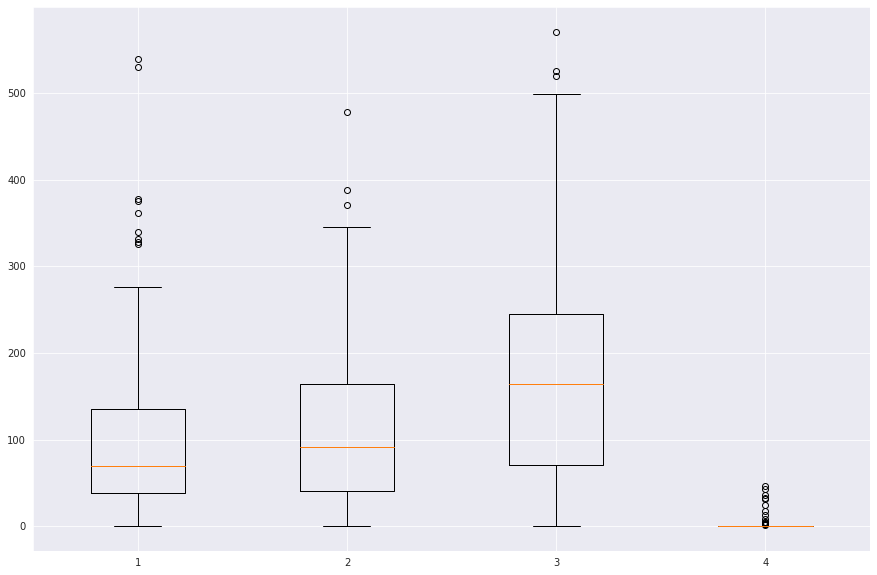

In [ ]:
rdn_gene_1 = random.randrange(filtered_cells.shape[0])
rdn_gene_2 = random.randrange(filtered_cells.shape[0])
rdn_gene_3 = random.randrange(filtered_cells.shape[0])
rdn_gene_4 = random.randrange(filtered_cells.shape[0])

plt.figure(figsize=(15, 10))
plt.boxplot(x = [filtered_cells.iloc[rdn_gene_1, :],
                 filtered_cells.iloc[rdn_gene_2, :],
                 filtered_cells.iloc[rdn_gene_3, :],
                 filtered_cells.iloc[rdn_gene_4, :]
                ])

This is why we proceed in a way that is analogus to the one proposed above but we use a non-parametric test to obrain the p-values, that is the **Wilcoxon-Mann-Whitney test** (alson known as the **Mann-Whitney U test**)

In [ ]:
p_val_row_np = {}
for i in range(np_filt_1.shape[0]):
  p_val_row_np[i] = stats.mannwhitneyu(x=hypo_np.iloc[i,:], y=norm_np.iloc[i,:], alternative = 'two-sided').pvalue


/usr/local/lib/python3.7/dist-packages/scipy/stats/stats.py:6415: RuntimeWarning: divide by zero encountered in double_scalars
  z = (bigu - meanrank) / sd


ValueError: ignored

We now proceed following the same structure as what we did before, just adapting the function used above.

Text(0.5, 1.0, 'p-value histogram')

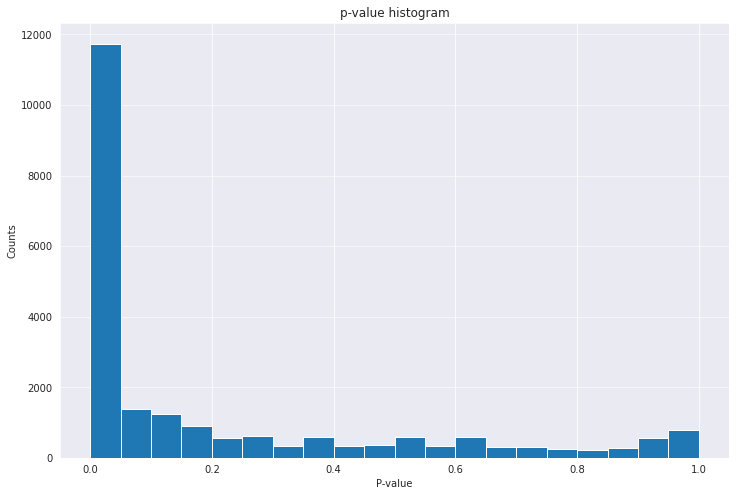

In [ ]:
plt.figure(figsize=(12,8))
plt.hist(p_val_row_np.values(),
         bins = 20)
plt.grid(axis='y', alpha=0.75)
plt.xlabel('P-value')
plt.ylabel('Counts')
plt.title('p-value histogram')

In [ ]:
def filter_CPM_np(treshold):
  '''
  This function takes as input a CPM trashold and then it looks for each gene if there are
  at least two cells with the CPM that is over the given trashold. It then stores the indices
  of the genes that did NOT pass this barrier test.
  '''
  to_filter_list = []
  for i in range(np_filt_1.shape[0]):
    mask = [element for element in np_filt_1.iloc[i,:] if element >= treshold]
    if len(mask) <= 2:
      to_filter_list.append(i)
  return to_filter_list

In [ ]:
def graph_data_due_np(p_val_pre):
  y_axis = []
  for treshold in np.arange(0, 20, 1):
    aux_dictt = p_val_pre.copy()
    indices = filter_CPM_np(treshold)
    print("how many genes will be ignored in this iteration", len(indices))
    for ind in indices:
      del aux_dictt[ind]
    count = len([value for value in q_value(aux_dictt) if value[1] <= 0.05])
    print("Relevant number of genes for this treshold", count)
    y_axis.append(count)
    aux_dictt = p_val_pre.copy()
  return y_axis

In [ ]:
y = graph_data_due_np(p_val_row_np)

how many genes will be ignored in this iteration 0
Relevant number of genes for this treshold 10757
how many genes will be ignored in this iteration 1375
Relevant number of genes for this treshold 10856
how many genes will be ignored in this iteration 3457
Relevant number of genes for this treshold 10843
how many genes will be ignored in this iteration 4346
Relevant number of genes for this treshold 10733
how many genes will be ignored in this iteration 4942
Relevant number of genes for this treshold 10633
how many genes will be ignored in this iteration 5383
Relevant number of genes for this treshold 10550
how many genes will be ignored in this iteration 5800
Relevant number of genes for this treshold 10438
how many genes will be ignored in this iteration 6098
Relevant number of genes for this treshold 10351
how many genes will be ignored in this iteration 6365
Relevant number of genes for this treshold 10260
how many genes will be ignored in this iteration 6608
Relevant number of gen

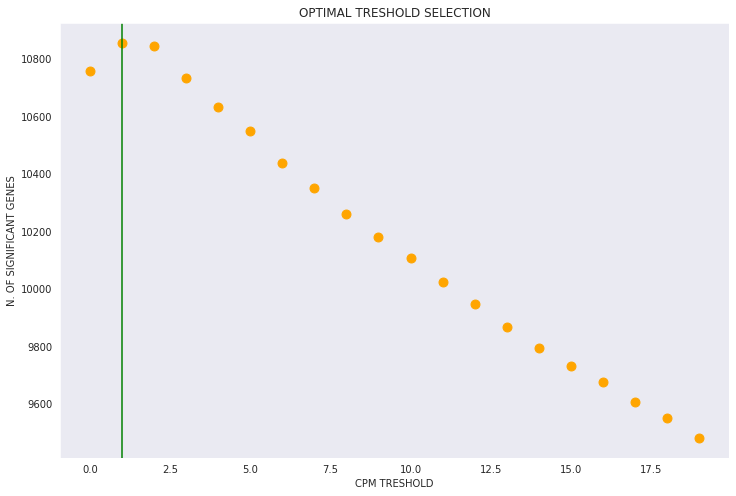

In [ ]:
x = np.arange(0, 20, 1)
plt.figure(figsize=(12,8))
plt.scatter(x, y,
            s = 80,
            color = "orange")
plt.grid()
plt.xlabel('CPM TRESHOLD')
plt.ylabel('N. OF SIGNIFICANT GENES')
plt.title('OPTIMAL TRESHOLD SELECTION')
plt.axvline(x=1, color = "green")
plt.show()

In [ ]:
#We calculate the optimal set of genes
indices_np = filter_CPM_np(2)
final_dictt_np = p_val_row_np.copy()

for ind in indices_np:
  del final_dictt_np[ind]

#Notice that the sensitivity setted is very very small: 0.001%
final_indices_np = [value[0] for value in q_value(final_dictt_np) if (value[1] <= 0.00001)]

In [ ]:
filt_lollo_2 = filtered_cells.copy().iloc[final_indices_np]
filt_lollo_2

,output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam,output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam,output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam,output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam,output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam,output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam,output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam,output.STAR.1_B10_Hypo_S76_Aligned.sortedByCoord.out.bam,output.STAR.1_B11_Hypo_S77_Aligned.sortedByCoord.out.bam,output.STAR.1_B12_Hypo_S78_Aligned.sortedByCoord.out.bam,...,output.STAR.4_H10_Hypo_S382_Aligned.sortedByCoord.out.bam,output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam,output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam,output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam,output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam,output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam,output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam,output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam,output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam,output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam
MTND2P28,2,1,0,1,3,6,16,15,3,0,...,0,0,4,2,1,0,2,7,29,5
MTCO1P12,2,1,0,3,10,5,5,1,5,2,...,0,1,7,4,0,1,5,0,4,3
MTCO2P12,0,1,0,0,1,2,1,0,0,0,...,0,0,1,1,0,0,5,0,0,0
MTATP6P1,29,12,68,203,691,206,766,331,46,27,...,25,50,294,214,131,49,370,33,228,71
MTCO3P12,0,0,0,0,2,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZMAT5,30,0,15,75,24,19,59,0,19,20,...,0,13,32,42,31,20,0,44,22,92
UQCR10,68,256,167,386,549,323,251,376,238,114,...,259,60,208,420,181,166,354,115,113,201
HORMAD2-AS1,0,12,0,2,0,3,0,7,4,0,...,0,0,3,1,0,0,0,3,7,5
CNN2P1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
counter = 0
for gene in proffilt.index.values:
  if gene in filt_lollo_2.index.values:
    counter +=1

print(f"Sovrapposition between our dataframe and provided dataframe: {counter/3000 *100}%")

Sovrapposition between our dataframe and provided dataframe: 23.799999999999997%


We see hat now the allignment with the provided dataframe is worse than before (this is expected as the data now are not normalized as before)

---

#PCA (interactive version)  

- Produce different kind of clustering and compare them to one another using different metrics (ability of predicting the clusters, ability to reconstruct the data..)
- We can decide to cluster on the PCA or on the genes directly
- Use the genes I know will be relevan as prior for classifier

In [ ]:
proffilt = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/AILAB/MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt', delimiter = " ", index_col = 0)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
three_dim = pca.fit_transform(proffilt.T)

plot_df = pd.DataFrame(three_dim)
plot_df.columns = ["PC1","PC2","PC3"]

aux_lst = []
for name in proffilt.columns:
  if meta.loc[name][3] == 'Hypo':
    aux_lst.append("Hypoxic")
  else:
    aux_lst.append("Normoxic")

plot_df["Color"] = aux_lst
plot_df

,PC1,PC2,PC3,Color
0,-26874.672396,766.013957,-880.248210,Normoxic
1,-26354.743000,5039.849020,-5372.826813,Normoxic
2,-29351.253485,2414.726753,-3076.254100,Normoxic
3,-24813.833293,-75.979072,-3934.877140,Normoxic
4,4454.732179,-1836.273354,-1595.912687,Hypoxic
...,...,...,...,...
245,-18394.340467,-5274.416642,649.525625,Normoxic
246,-10023.164045,-14507.616731,-1941.969651,Normoxic
247,603.697715,11492.308191,43230.690447,Hypoxic
248,17016.931253,8398.335833,4439.884797,Hypoxic


In [ ]:
!pip install jupyter-dash

import plotly.graph_objects as go
import plotly.express as px
from jupyter_dash import JupyterDash
import dash_core_components as dcc
import dash_html_components as html
from dash.dependencies import Input, Output

fig = px.scatter_3d(
    data_frame = plot_df,
    x = "PC1",
    y = "PC2",
    z = "PC3",
    color = "Color",
    title="Interactive PCA plot with supervised labels",
)

# build jupyter dash app
app = JupyterDash(__name__)
# add html components and figure to app
app.layout = html.Div([dcc.Graph(figure=fig)])
# run app inline
app.run_server(mode='inline')

<IPython.core.display.Javascript object>

---
#Neural Network for HCC1806 Cells

In [ ]:
import sklearn
assert sklearn.__version__ >= "0.20"
from sklearn.model_selection import train_test_split

import tensorflow as tf
assert tf.__version__ >= "2.0"

import numpy as np
import pandas as pd

from tensorflow import keras
from keras.layers import Dense, Input, Flatten
from keras.models import Sequential

import pandas as pd

%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt

In [ ]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

try:
    # %tensorflow_version only exists in Colab.
    %tensorflow_version 2.x
except Exception:
    pass

# TensorFlow ≥2.0 is required
import tensorflow as tf
assert tf.__version__ >= "2.0"

# Common imports
import numpy as np
import os

# to make this notebook's output stable across runs


# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Where to save the figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "ann"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)


---
---

In [ ]:
df_meta = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AILAB/HCC1806_SmartS_MetaData.tsv", delimiter = "\t", header=0)
df_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AILAB/HCC1806_SmartS_Filtered_Normalised_3000_Data_train.txt", sep = " ")

df_meta["Condition"] = df_meta.Condition.eq('Hypo').mul(1)
df_meta[["Filename", "Condition"]]

lables= []
for j in list(df_train.columns):
    for i , h in zip(df_meta["Filename"], df_meta["Condition"]):
        if j == i:
            lables.append(h)
print(lables)
print(len(lables))

[0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0]
182


In [ ]:
X = df_train.to_numpy()
X = np.transpose(X)

X = pd.DataFrame(X)
X

,0,1,2,3,4,5,6,7,8,9,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
0,0,48,0,321,298,82,6250,634,0,0,...,78,10,136,0,0,29,0,29,0,0
1,8739,2101,55,96,1824,1938,62,0,522,413,...,279,0,264,0,134,68,0,213,0,0
2,13098,14032,0,0,1616,247,430,907,348,0,...,311,0,38,0,0,0,0,92,0,0
3,2880,356,0,6211,3,3430,79,1953,592,176,...,125,0,16,0,4,1,0,1,0,0
4,7777,5661,4383,0,145,4618,246,85,206,0,...,268,1,25,0,0,0,0,128,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177,79,5,0,2098,554,99,798,4211,64,0,...,11,0,264,0,10,34,0,24,0,0
178,167,1,0,27,3585,134,3,596,11,0,...,251,0,120,25,0,53,0,177,53,0
179,10186,3147,0,149,1012,111,716,617,744,0,...,94,0,55,0,157,43,0,113,0,0
180,238,41,2867,814,2207,297,1023,2879,1,0,...,149,0,42,0,26,0,0,13,5,0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
         X, lables, test_size=0.20, random_state=42)

In [ ]:
np_X_train = np.array(X_train)
X_test = np.array(X_test)
np_y_train = np.array(y_train)
y_test = np.array(y_test)

np_X_train.shape
tot = np_X_train.max()

X_valid, X_train = np_X_train[120:] / tot, np_X_train[:120] /tot
y_valid, y_train = np_y_train[120:], np_y_train[:120]
X_test = X_test / tot

X_train

array([[3.06695425e-03, 3.73130933e-04, 8.23618278e-03, ...,
        7.64463374e-04, 0.00000000e+00, 0.00000000e+00],
       [3.16706255e-03, 9.10075445e-06, 0.00000000e+00, ...,
        9.10075445e-05, 0.00000000e+00, 0.00000000e+00],
       [9.45386373e-02, 2.69109309e-02, 0.00000000e+00, ...,
        1.74734485e-03, 1.24680336e-03, 5.18743004e-04],
       ...,
       [5.53143856e-02, 4.75332405e-02, 5.11462400e-03, ...,
        6.00649794e-04, 0.00000000e+00, 0.00000000e+00],
       [6.03380020e-03, 9.10075445e-06, 6.37052812e-05, ...,
        1.41061694e-03, 0.00000000e+00, 0.00000000e+00],
       [8.57746107e-02, 6.19761378e-03, 0.00000000e+00, ...,
        5.64246776e-04, 0.00000000e+00, 0.00000000e+00]])

In [ ]:
early_stopping_cb = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
checkpoint_cb = keras.callbacks.ModelCheckpoint("my_keras_model", save_best_only=True)

In [ ]:
model = keras.models.Sequential()
model.add(Dense(units=3000, activation= "relu", input_shape= (3000,))) # input_shape doesn't include batch dimension (not aware of how many images i have), flatten layer is the input layer, we just take the 28x28 matrix and we turn into a vector of lenght 784
model.add(keras.layers.Dense(5000, activation="relu"))
model.add(keras.layers.Dense(500, activation="relu"))
model.add(keras.layers.Dense(1, activation = 'sigmoid'))

model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),  #This cross entropy works with not hot-encoded lables, from_logits=False if we use a softmax, we will use binary cross entropy with one final node for our task
              optimizer=keras.optimizers.SGD(learning_rate= 0.1),  #Stochastic Gradient Descent
              metrics=["accuracy"]) #This is monitored but not part of the optimization problem


history = model.fit(X_train, y_train, epochs=70,
                    validation_data=(X_valid, y_valid))




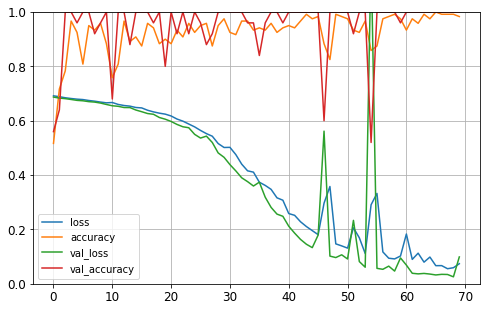

In [ ]:
import pandas as pd

pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show()

---
# NN for HCC Dropseq

In [ ]:
#Here we load the data from the Drive
df_train_HCC = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AILAB/HCC1806_Filtered_Normalised_3000_Data_train.txt", sep=" ")

In [ ]:
namesH = df_train_HCC.columns.values

df_train_HCC_t = df_train_HCC.T.copy()
df_train_HCC_t["Classification"] = [i for i in range(len(namesH))]

for i in range(len(namesH)):
    if "Hypo" in namesH[i]:
        df_train_HCC_t["Classification"][i] = 1
    else:
        df_train_HCC_t["Classification"][i] = 0

from sklearn.model_selection import train_test_split

X = df_train_HCC_t.copy().iloc[:,:-1]
y = pd.DataFrame(df_train_HCC_t.copy()["Classification"])

#Changed here the test_size from 0.33 to 0.2
X_train, X_test, y_train, y_test = train_test_split(X.copy(), y.copy(), test_size=0.2, random_state = 42)

In [ ]:
y_train

,Classification
CTCCACTAGAGG_Normoxia,0
ATGTTGCGATTA_Hypoxia,1
TGCGCAGACAAC_Normoxia,0
GAGCGAACGGAC_Hypoxia,1
CCTTCCATCATC_Hypoxia,1
...,...
TCTGGCAGGATC_Normoxia,0
TCCCACCCTAGA_Hypoxia,1
TGCTTGGTCCCC_Normoxia,0
ATGTCCAGGCTA_Normoxia,0


In [ ]:
X_train

In [ ]:
x_valid, x_train = X_train[:1000], X_train[1000:]
y_valid, y_train = y_train[:1000], y_train[1000:]

pd.DataFrame(X_train)

,H1-5,MALAT1,MT-RNR2,ARVCF,BCYRN1,ATXN7L2,IGFBP3,H1-3,CTIF,RNF123,...,BATF3,CDKN3,DLD,PMPCA,ZNF165,SCCPDH,NTAN1,CLIP2,DUSP23,ZNF682
CTCCACTAGAGG_Normoxia,3,3,0,0,2,0,1,2,0,0,...,0,0,0,0,0,0,0,0,0,0
ATGTTGCGATTA_Hypoxia,3,3,0,0,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
TGCGCAGACAAC_Normoxia,0,0,0,0,5,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GAGCGAACGGAC_Hypoxia,0,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CCTTCCATCATC_Hypoxia,0,0,2,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCTGGCAGGATC_Normoxia,2,8,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
TCCCACCCTAGA_Hypoxia,0,2,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
TGCTTGGTCCCC_Normoxia,2,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ATGTCCAGGCTA_Normoxia,0,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
model = keras.models.Sequential()
model.add(Dense(units=3000, activation= "relu", input_shape= (3000,))) # input_shape doesn't include batch dimension (not aware of how many images i have), flatten layer is the input layer, we just take the 28x28 matrix and we turn into a vector of lenght 784
model.add(keras.layers.Dense(3500, activation="relu"))
model.add(keras.layers.Dense(300, activation="relu"))
model.add(keras.layers.Dense(1, activation = 'sigmoid'))

model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),  #This cross entropy works with not hot-encoded lables, from_logits=False if we use a softmax, we will use binary cross entropy with one final node for our task
              optimizer=keras.optimizers.SGD(learning_rate= 0.01),  #Stochastic Gradient Descent
              metrics=["accuracy"]) #This is monitored but not part of the optimization problem


history = model.fit(x_train, y_train, epochs=10,
                    validation_data=(x_valid, y_valid))

 28/336 [=>............................] - ETA: 38s - loss: 0.6521 - accuracy: 0.6395

KeyboardInterrupt: ignored

In [ ]:
model.evaluate(X_test, y_test)

92/92 [==============================] - 2s 24ms/step - loss: 0.1334 - accuracy: 0.9489


[0.13343657553195953, 0.9489274621009827]

----

In [ ]:
epochs = 10

# define the optimizer function
rms = keras.optimizers.RMSprop(lr=0.001, rho=0.9, epsilon=None, decay=0.0)

input_dim = x_train.shape[1]
num_classes = 1
batch_size = 200

# build the model
exponential_decay_model = Sequential()
exponential_decay_model.add(Dense(3200, activation=tf.nn.relu, kernel_initializer='uniform', input_dim = input_dim, kernel_regularizer=keras.regularizers.l2(0.1)))
exponential_decay_model.add(keras.layers.Dropout(0.1))
exponential_decay_model.add(Dense(32, kernel_initializer='uniform', activation=tf.nn.relu, kernel_regularizer=keras.regularizers.l2(0.1)))
exponential_decay_model.add(Dense(num_classes, kernel_initializer='uniform', activation = 'sigmoid'))

# compile the model
exponential_decay_model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
                                optimizer=rms,
                                metrics=['acc'])


# learning schedule callback
loss_history = keras.callbacks.History()


# you invoke the LearningRateScheduler during the .fit() phase
exponential_decay_model_history = exponential_decay_model.fit(x_train, y_train,
                                    batch_size=batch_size,
                                    epochs=epochs,

                                    verbose=1,
                                    validation_data=(x_valid, y_valid))

/usr/local/lib/python3.7/dist-packages/keras/optimizer_v2/rmsprop.py:130: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super(RMSprop, self).__init__(name, **kwargs)


Epoch 1/10


/usr/local/lib/python3.7/dist-packages/tensorflow/python/util/dispatch.py:1082: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a sigmoid or softmax activation and thus does not represent logits. Was this intended?"
  return dispatch_target(*args, **kwargs)


54/54 [==============================] - ETA: 0s - loss: 142.3625 - acc: 0.6161

/usr/local/lib/python3.7/dist-packages/tensorflow/python/util/dispatch.py:1082: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a sigmoid or softmax activation and thus does not represent logits. Was this intended?"
  return dispatch_target(*args, **kwargs)


54/54 [==============================] - 16s 268ms/step - loss: 142.3625 - acc: 0.6161 - val_loss: 1.4113 - val_acc: 0.6340
Epoch 2/10
54/54 [==============================] - 15s 274ms/step - loss: 0.8392 - acc: 0.6379 - val_loss: 0.9010 - val_acc: 0.9010
Epoch 3/10
54/54 [==============================] - 15s 272ms/step - loss: 0.8634 - acc: 0.7846 - val_loss: 0.8337 - val_acc: 0.7530
Epoch 4/10
54/54 [==============================] - 15s 270ms/step - loss: 0.8206 - acc: 0.8438 - val_loss: 0.7737 - val_acc: 0.8500
Epoch 5/10
54/54 [==============================] - 14s 268ms/step - loss: 0.7814 - acc: 0.8743 - val_loss: 0.7188 - val_acc: 0.9110
Epoch 6/10
54/54 [==============================] - 15s 271ms/step - loss: 0.7508 - acc: 0.8859 - val_loss: 0.6947 - val_acc: 0.9160
Epoch 7/10
54/54 [==============================] - 14s 263ms/step - loss: 0.7286 - acc: 0.8915 - val_loss: 0.6771 - val_acc: 0.9110
Epoch 8/10
54/54 [==============================] - 14s 264ms/step - loss: 0.7

In [ ]:
model.evaluate(X_test, y_test)

92/92 [==============================] - 4s 43ms/step - loss: 0.6018 - accuracy: 0.8029


[0.6018368601799011, 0.8028600811958313]

In [ ]:
import numpy
from sklearn.model_selection import GridSearchCV
from keras.wrappers.scikit_learn import KerasClassifier


# let's create a function that creates the model (required for KerasClassifier)
# while accepting the hyperparameters we want to tune
# we also pass some default values such as optimizer='rmsprop'
def create_model(init_mode='uniform'):
    # define model
    model = Sequential()
    model.add(Dense(3200, kernel_initializer=init_mode, activation=tf.nn.relu, input_dim=x_train.shape[1]))
    model.add(keras.layers.Dropout(0.1))
    model.add(Dense(32, kernel_initializer=init_mode, activation=tf.nn.relu))
    model.add(Dense(1, kernel_initializer=init_mode, activation = 'sigmoid'))
    # compile model
    model.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer=keras.optimizers.RMSprop(),
              metrics=['accuracy'])
    return model

In [ ]:

batch_size = 128
epochs = 10

model_CV = KerasClassifier(build_fn=create_model, epochs=epochs,
                           batch_size=batch_size, verbose=1)
# define the grid search parameters
init_mode = ['uniform', 'lecun_uniform', 'normal', 'zero',
             'glorot_normal', 'glorot_uniform', 'he_normal', 'he_uniform']

param_grid = dict(init_mode=init_mode)
grid = GridSearchCV(estimator=model_CV, param_grid=param_grid, n_jobs=-1, cv=3)
grid_result = grid.fit(x_train, y_train)

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:6: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  


KeyboardInterrupt: ignored

In [ ]:
# print results
print(f'Best Accuracy for {grid_result.best_score_} using {grid_result.best_params_}')
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print(f' mean={mean:.4}, std={stdev:.4} using {param}')